In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import ipaddress
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/final_data.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2099976 entries, 0 to 2099975
Data columns (total 16 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Src IP              object 
 1   Src Port            int64  
 2   Dst IP              object 
 3   Dst Port            int64  
 4   Protocol            int64  
 5   Total Fwd Packet    int64  
 6   Packet Length Min   int64  
 7   Packet Length Max   int64  
 8   Packet Length Mean  float64
 9   FIN Flag Count      int64  
 10  SYN Flag Count      int64  
 11  RST Flag Count      int64  
 12  PSH Flag Count      int64  
 13  ACK Flag Count      int64  
 14  URG Flag Count      int64  
 15  Label               object 
dtypes: float64(1), int64(12), object(3)
memory usage: 256.3+ MB


This section loads the dataset and performs preprocessing. IP addresses are converted to numerical values, attack labels are encoded into numeric form, and selected numerical features are normalized. Additionally, a 'Padding' column is added to the dataset to maintain a uniform structure for further processing.

In [ ]:
df['Src IP'] = df['Src IP'].apply(lambda x: int(ipaddress.IPv4Address(x)))
df['Dst IP'] = df['Dst IP'].apply(lambda x: int(ipaddress.IPv4Address(x)))

# Step 2: Encode the 'Label' column (attack type) to numeric values
label_encoder = LabelEncoder()
df['Label'] = label_encoder.fit_transform(df['Label'])

# Step 3: Normalize numerical columns
scaler = StandardScaler()
features = ['Src IP', 'Dst IP', 'Src Port', 'Dst Port', 'Protocol',
                'Total Fwd Packet', 'Packet Length Min', 'Packet Length Max',
                'Packet Length Mean', 'FIN Flag Count', 'SYN Flag Count',
                'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count']

df[features] = scaler.fit_transform(df[features])
df['Padding'] = 0
features.append('Padding')
df


,Src IP,Src Port,Dst IP,Dst Port,Protocol,Total Fwd Packet,Packet Length Min,Packet Length Max,Packet Length Mean,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,Label,Padding
0,0.469770,0.042106,0.450297,-0.138244,-0.950134,-0.002896,-0.798264,-0.559742,-0.720683,-0.690878,-0.886529,-0.455106,-0.111989,-0.002014,-0.005787,0,0
1,-19.047978,-3.039116,-3.293542,-0.214698,-2.040644,0.015487,-0.798264,-0.560184,-0.722387,-0.690878,-0.886529,-0.455106,-0.111989,-0.011876,-0.005787,0,0
2,0.469770,-3.031407,0.450297,-0.193566,1.049135,-0.009790,1.038085,-0.539007,-0.558845,-0.690878,-0.886529,-0.455106,-0.111989,-0.011876,-0.005787,0,0
3,0.469770,0.739155,0.450297,-0.205592,1.049135,-0.013237,0.885056,-0.454299,-0.238574,-0.690878,-0.886529,-0.455106,-0.111989,-0.011876,-0.005787,0,0
4,0.469770,0.846649,0.450297,-0.205592,1.049135,-0.013237,1.038085,-0.524889,-0.504331,-0.690878,-0.886529,-0.455106,-0.111989,-0.011876,-0.005787,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2099971,0.469771,0.798826,0.450297,3.491333,-0.950134,-0.012088,-0.798264,-0.560184,-0.722387,-0.690878,0.987980,1.697378,-0.111989,-0.010890,-0.005787,17,0
2099972,0.469771,0.430463,0.450297,-0.205592,1.049135,-0.012088,0.655512,-0.536360,-0.565659,-0.690878,-0.886529,-0.455106,-0.111989,-0.011876,-0.005787,0,0
2099973,0.469771,0.942485,0.450297,-0.205592,1.049135,-0.012088,0.425968,-0.514300,-0.490702,-0.690878,-0.886529,-0.455106,-0.111989,-0.011876,-0.005787,0,0
2099974,0.469771,0.426890,0.450297,-0.210918,-0.950134,0.033869,-0.798264,-0.129586,-0.363631,3.398925,2.862489,-0.455106,1.588512,0.030532,-0.005787,0,0


This section prepares the dataset for training a Convolutional Neural Network (CNN). The feature matrix is reshaped to fit the expected input format of the CNN. The data is then converted to PyTorch tensors, split into training and testing sets, and loaded into DataLoader objects for efficient batch processing. The script also detects and utilizes a GPU if available to accelerate computations

In [ ]:
X = df[features].values
y = df['Label'].values

# Reshape X to fit CNN input (N, 4, 4, 1)
X = X.reshape(-1, 1, 4, 4)
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [ ]:

train_data = torch.utils.data.TensorDataset(X_train, y_train)
test_data = torch.utils.data.TensorDataset(X_test, y_test)

train_loader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=128, shuffle=False)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on: {device}")

Running on: cuda


This section defines a Convolutional Neural Network (CNN) architecture for anomaly detection. The model consists of two convolutional layers followed by max-pooling operations to extract spatial features. A fully connected layer with dropout is used to prevent overfitting before the final classification layer, which outputs the predicted class labels

In [ ]:
class CNNAnomalyDetector(nn.Module):
    def __init__(self, num_classes):
        super(CNNAnomalyDetector, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 1 * 1, 128)
        self.dropout = nn.Dropout(p=0.55)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.flatten(x)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

This section initializes and trains the CNN-based anomaly detection model. The model is configured with a cross-entropy loss function and an Adam optimizer. The training loop runs for a specified number of epochs, iterating over the batches from the training set, computing the loss, updating the weights, and tracking accuracy. The model is trained on a GPU if available to improve performance.

In [ ]:
# Initialize model
num_classes = len(label_encoder.classes_)  # Number of attack types
model = CNNAnomalyDetector(num_classes)

# Define optimizer and loss function
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# Training loop
num_epochs = 15
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == batch_y).sum().item()
        total += batch_y.size(0)

    train_acc = correct / total
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss:.4f}, Accuracy: {train_acc:.4f}')


Epoch [1/15], Loss: 947.5942, Accuracy: 0.9734
Epoch [2/15], Loss: 581.6874, Accuracy: 0.9805
Epoch [3/15], Loss: 539.4259, Accuracy: 0.9817
Epoch [4/15], Loss: 514.3834, Accuracy: 0.9823
Epoch [5/15], Loss: 497.1630, Accuracy: 0.9829
Epoch [6/15], Loss: 479.3428, Accuracy: 0.9840
Epoch [7/15], Loss: 500.9472, Accuracy: 0.9837
Epoch [8/15], Loss: 475.5816, Accuracy: 0.9845
Epoch [9/15], Loss: 463.0372, Accuracy: 0.9845
Epoch [10/15], Loss: 447.6865, Accuracy: 0.9853
Epoch [11/15], Loss: 447.4995, Accuracy: 0.9853
Epoch [12/15], Loss: 457.5449, Accuracy: 0.9846
Epoch [13/15], Loss: 462.3869, Accuracy: 0.9846
Epoch [14/15], Loss: 452.9231, Accuracy: 0.9849
Epoch [15/15], Loss: 450.2196, Accuracy: 0.9849


In [ ]:
torch.save(model.state_dict(), "cnn2d_model.pth")
print("Model saved as cnn2d_model.pth")

Model saved as cnn2d_model.pth


This section loads the trained CNN model and evaluates its performance on the test dataset. The model's predictions are compared with actual labels, and key evaluation metrics such as accuracy, precision, recall, and F1-score are computed. A classification report is also generated to provide a detailed breakdown of the model’s performance across different classes.

In [ ]:

model = model = CNNAnomalyDetector(num_classes).to(device)
model.load_state_dict(torch.load("cnn2d_model.pth", weights_only=True))
# Evaluate model
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        outputs = model(batch_X)
        _, predicted = torch.max(outputs, 1)
        y_true.extend(batch_y.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')
class_report = classification_report(y_true, y_pred)

# Print results
print(f'Test Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')
print("Classification Report:")
print(class_report)

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Test Accuracy: 0.9852
Precision: 0.9856
Recall: 0.9852
F1 Score: 0.9852
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    316165
           1       1.00      1.00      1.00       160
           2       1.00      1.00      1.00       810
           3       0.83      0.91      0.87     19158
           4       0.93      0.83      0.88      1508
           5       0.00      0.00      0.00        12
           6       0.93      0.89      0.91     31734
           7       0.82      0.52      0.63       128
           8       0.96      0.99      0.97       345
           9       0.98      0.99      0.99       683
          10       0.99      0.99      0.99       814
          11       0.86      0.99      0.92       373
          12       1.00      0.99      1.00       751
          14       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         4
          16       0.00      0.00      0

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


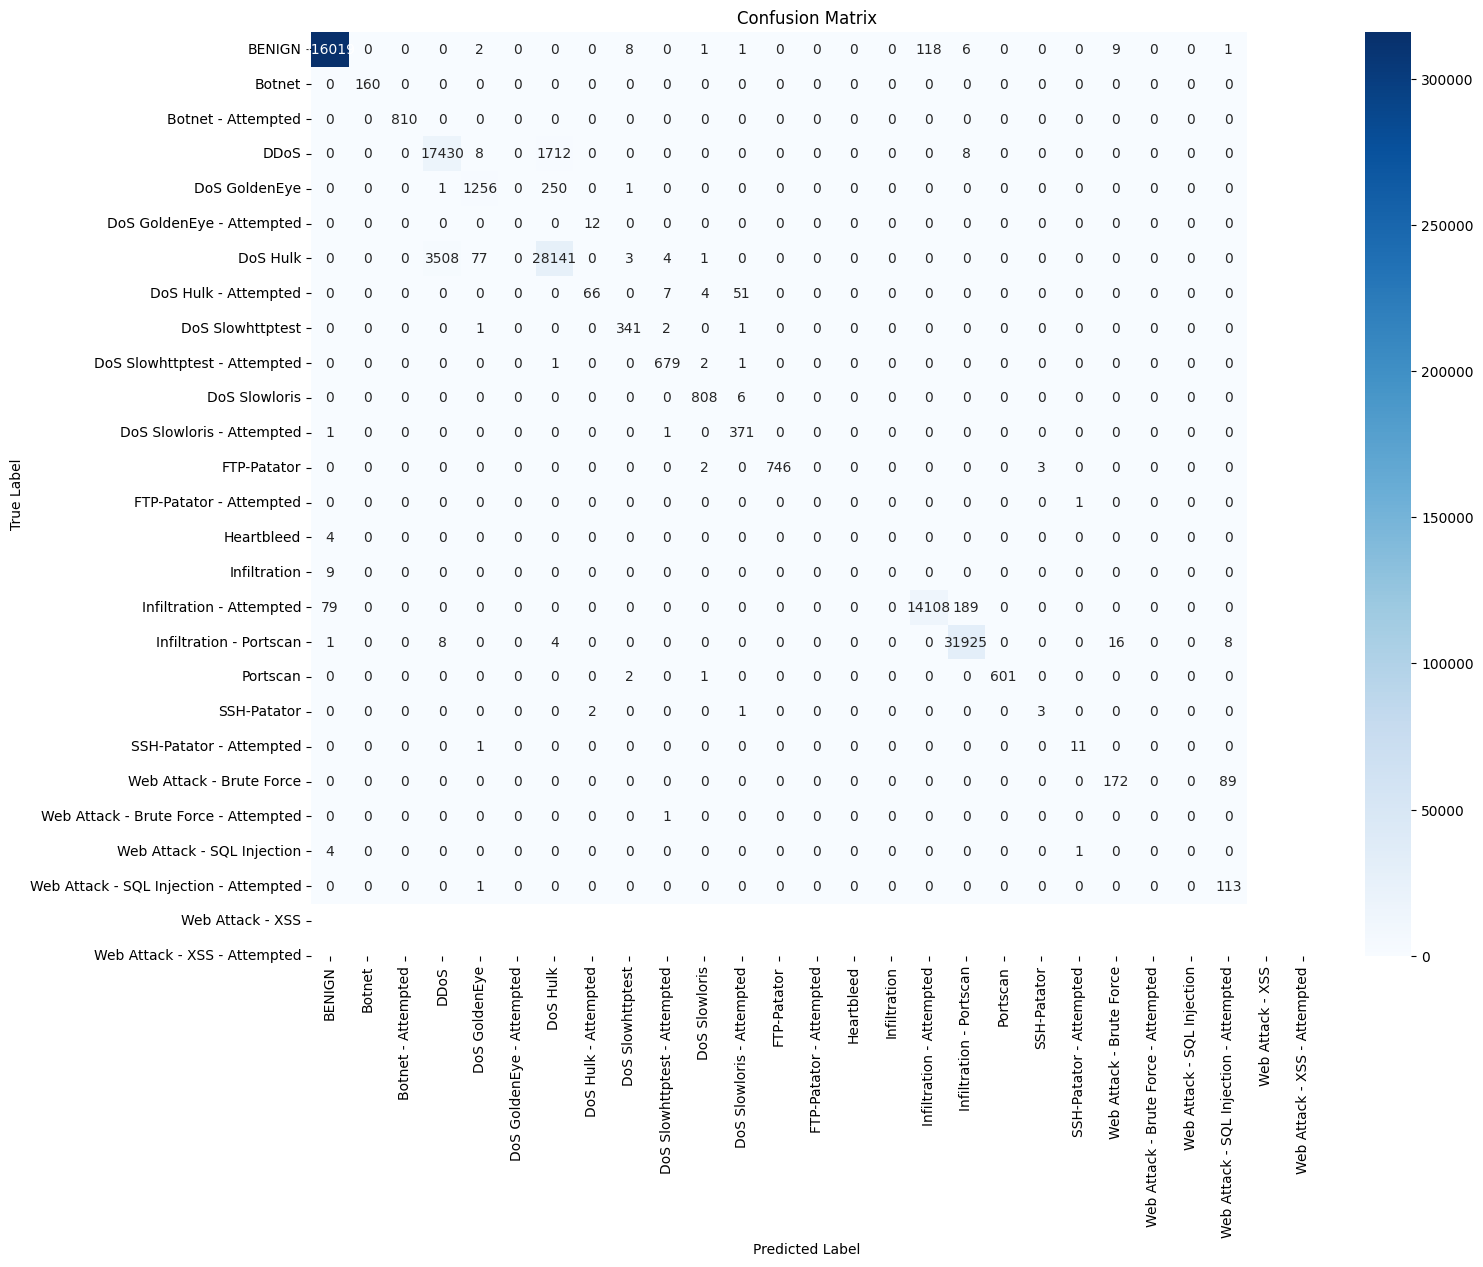

In [ ]:

cm = confusion_matrix(y_true, y_pred)

# Get class labels
class_labels = label_encoder.classes_

# Plot confusion matrix
plt.figure(figsize=(16, 12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
torch.save(model.state_dict(), "cnn2d_model.pth")
print("Model saved as resnet1d_model.pth")
